PART A - DATASET PREPARATION

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras.datasets import mnist

In [4]:
(x_train,y_train),(x_test,y_test)=mnist.load_data()

print("Training data shape:",x_train.shape)
print("Testing data shape:",x_test.shape)
print("Data type:",x_train.dtype)

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)
Data type: uint8


In [5]:
x_train=x_train.astype('float32')/255.0
x_test=x_test.astype('float32')/255.0

x_train=x_train.reshape(-1,784)
x_test=x_test.reshape(-1,784)
print("After reshaping:")
print("Training data shape:",x_train.shape)
print("Testing data shape:",x_test.shape)

After reshaping:
Training data shape: (60000, 784)
Testing data shape: (10000, 784)


In [6]:
y_train=x_train.copy()
y_test=x_test.copy()

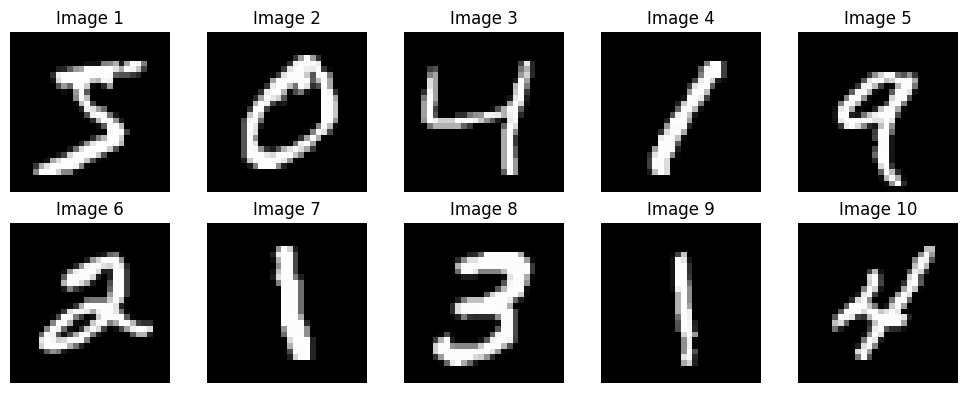

In [7]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title("Digit " + str(y_train[i].argmax()) if False else "Image " + str(i+1))
    plt.axis('off')

plt.tight_layout()
plt.show()

PART B: IMPLEMENTING THE AUTOENCODER MODEL

In [8]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [9]:
input_layer=Input(shape=(784,))
encoder=Dense(128,activation='relu')(input_layer)
bottleneck=Dense(32,activation='relu')(encoder)
decoder=Dense(128,activation='relu')(bottleneck)

output_layer=Dense(784,activation='sigmoid')(decoder)
autoencoder=Model(input_layer,output_layer)


In [10]:
autoencoder.compile(optimizer='adam',loss='mse')
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

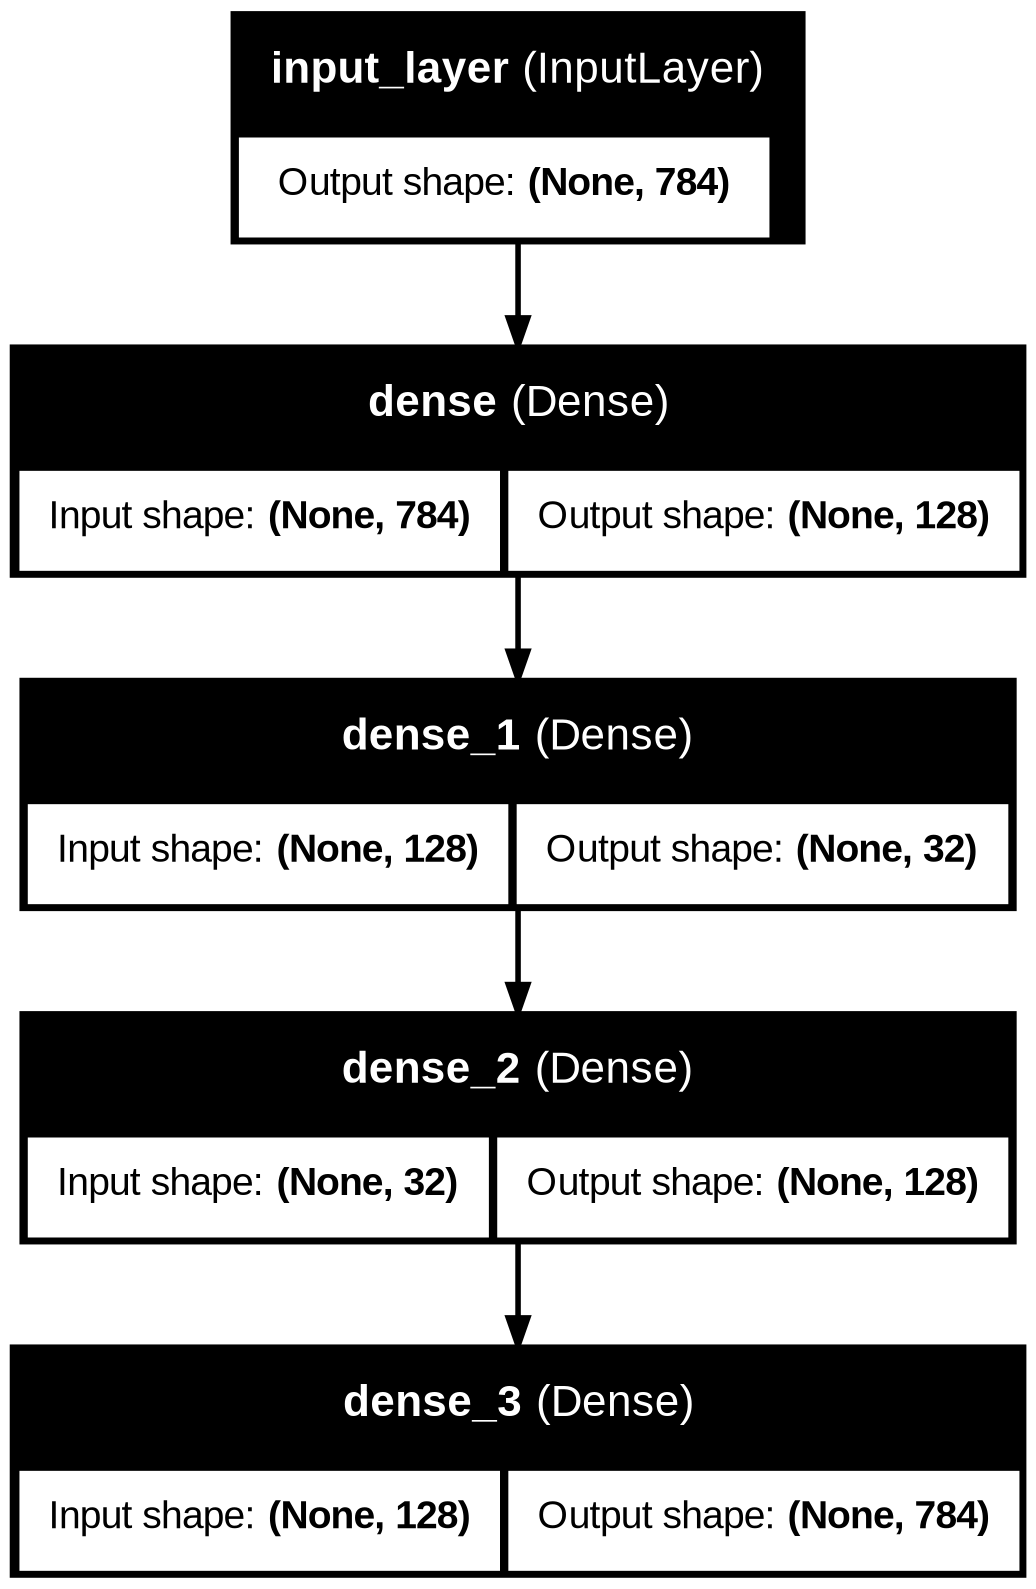

In [11]:
from tensorflow.keras.utils import plot_model

plot_model(
    autoencoder,
    show_shapes=True,
    show_layer_names=True
)

PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

In [12]:
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test)
)


Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0592 - val_loss: 0.0326
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.0261 - val_loss: 0.0210
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0189 - val_loss: 0.0165
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.0158 - val_loss: 0.0145
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0144 - val_loss: 0.0135
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 0.0135 - val_loss: 0.0129
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0129 - val_loss: 0.0122
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0123 - val_loss: 0.0116
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.0117 - val_loss: 0.0112
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - loss: 0.0113 - val_loss: 0.0110
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0110 - val_loss: 0.0106
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 

In [13]:
train_loss = history.history['loss']
val_loss = history.history['val_loss']

print("Training Loss:", train_loss[-1])
print("Validation Loss:", val_loss[-1])
test_loss = autoencoder.evaluate(x_test, x_test)

print("Test Loss:", test_loss)

reconstructed = autoencoder.predict(x_test)
mse = np.mean(np.square(x_test - reconstructed))

print("Reconstruction MSE:", mse)


Training Loss: 0.00936295185238123
Validation Loss: 0.009229275397956371
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0092
Test Loss: 0.009229278191924095
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Reconstruction MSE: 0.009229278


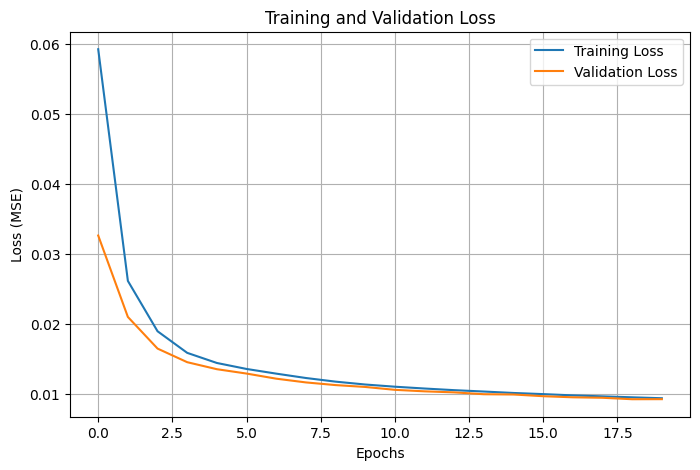

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.title('Training and Validation Loss')
plt.legend()
plt.grid()
plt.show()


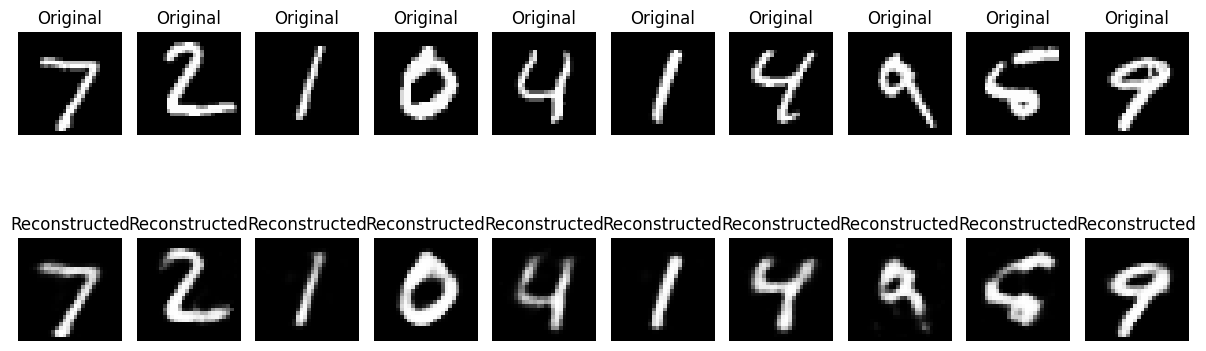

In [15]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title('Original')
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.title('Reconstructed')
    plt.axis('off')

plt.tight_layout()
plt.show()

PART D: DIMENSIONALITY REDUCTION, FEATURE VISUALIZATION AND EXPERIMENT MANAGEMENT

In [16]:
encoder_model = Model(
    inputs=autoencoder.input,
    outputs=autoencoder.layers[2].output
)

latent_features = encoder_model.predict(x_test)

print("Original Data Dimensions:", x_test.shape)
print("Compressed Data Dimensions:", latent_features.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Original Data Dimensions: (10000, 784)
Compressed Data Dimensions: (10000, 32)


In [17]:
print("Original Input Features:", x_test.shape[1])
print("Compressed Features:", latent_features.shape[1])

print("Dimensionality Reduced from",
      x_test.shape[1], "to", latent_features.shape[1])

Original Input Features: 784
Compressed Features: 32
Dimensionality Reduced from 784 to 32


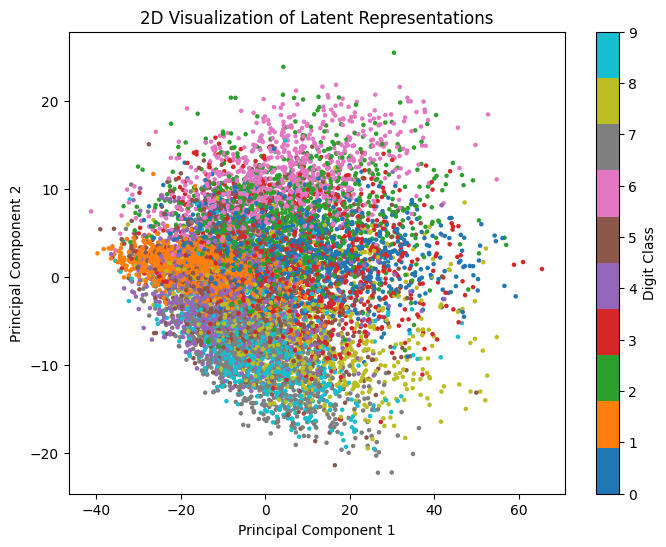

In [20]:
from sklearn.decomposition import PCA

# Load the original labels since y_test was overwritten with x_test.copy()
(_, _), (_, test_labels) = mnist.load_data()

pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_features)

plt.figure(figsize=(8, 6))

plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=test_labels,
    cmap='tab10',
    s=5
)

plt.colorbar(label='Digit Class')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2D Visualization of Latent Representations')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step


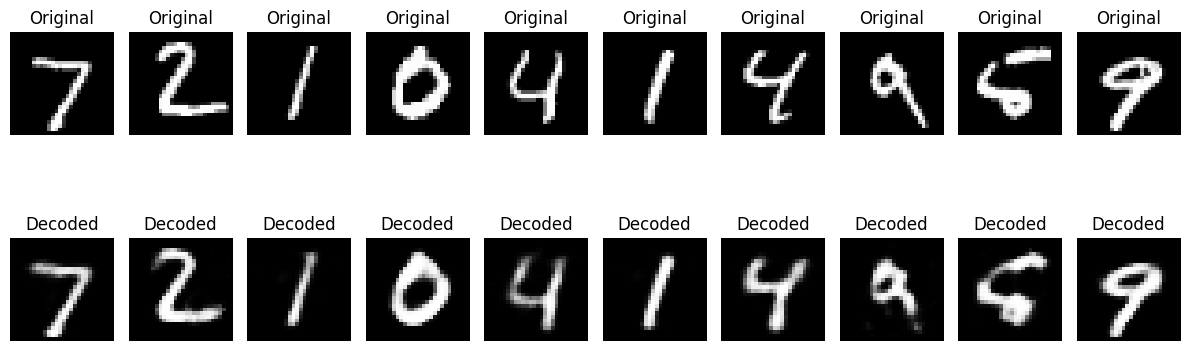

In [22]:
decoder_input = Input(shape=(32,))

decoder_output = autoencoder.layers[3](decoder_input)
decoder_output = autoencoder.layers[4](decoder_output)

decoder_model = Model(decoder_input, decoder_output)

# Select compressed test samples
selected_features = latent_features[:10]

# Reconstruct images using Decoder
decoded_images = decoder_model.predict(selected_features)

# Display original and reconstructed images
plt.figure(figsize=(12, 5))

for i in range(10):
    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title('Original')
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_images[i].reshape(28, 28), cmap='gray')
    plt.title('Decoded')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [23]:
original_features = x_test.shape[1]
compressed_features = latent_features.shape[1]

reduction = ((original_features - compressed_features)
             / original_features) * 100

print("Original Dimensions:", original_features)
print("Compressed Dimensions:", compressed_features)
print("Dimensionality Reduction:", reduction, "%")

Original Dimensions: 784
Compressed Dimensions: 32
Dimensionality Reduction: 95.91836734693877 %
